# Criteo 广告归因与预算效率分析

## 分析目标

本分析回答一个业务问题：

> 广告预算是否流向了真正影响转化的广告触点？

分析顺序固定为：

1. 看漏斗，找到最大业务异常。
2. 按活动下钻，判断预算是否集中在低效活动。
3. 按触点位置下钻，判断成本与归因信用是否错配。
4. 做敏感性和边界验证，避免把样本结构误读成因果结论。
5. 输出预算和触点出价建议。

## 数据边界

- 数据是 Criteo 归因研究样本，绝对 CPA 不能对标真实行业。
- `attribution` 是事件级字段，不是行级信用。
- 位置归因只使用首次和末次点击均可验证的完整路径。
- 频次与转化存在内生关系，不能直接解释为因果提升。

In [1]:
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path

FIGURE_DIR = Path("reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

con = duckdb.connect("data/criteo_analysis.duckdb")

con.execute("""
CREATE OR REPLACE VIEW raw AS
SELECT *
FROM read_csv(
    'data/raw/criteo_attribution_dataset.tsv',
    delim = '\t',
    header = true,
    columns = {
        'timestamp': 'BIGINT',
        'uid': 'BIGINT',
        'campaign': 'INTEGER',
        'conversion': 'TINYINT',
        'conversion_timestamp': 'BIGINT',
        'conversion_id': 'BIGINT',
        'attribution': 'TINYINT',
        'click': 'TINYINT',
        'click_pos': 'INTEGER',
        'click_nb': 'INTEGER',
        'cost': 'DOUBLE',
        'cpo': 'DOUBLE',
        'time_since_last_click': 'BIGINT',
        'cat1': 'INTEGER',
        'cat2': 'INTEGER',
        'cat3': 'INTEGER',
        'cat4': 'INTEGER',
        'cat5': 'INTEGER',
        'cat6': 'INTEGER',
        'cat7': 'INTEGER',
        'cat8': 'INTEGER',
        'cat9': 'INTEGER'
    }
)
""")

con.sql("DESCRIBE raw").show()

summary = con.sql("""
SELECT
    count(*) AS rows,
    count(DISTINCT uid) AS users,
    count(DISTINCT campaign) AS campaigns,
    min(timestamp) // 86400 AS first_day,
    max(timestamp) // 86400 AS last_day,
    sum(click) AS clicks,
    sum(conversion) AS conversion_rows,
    count(DISTINCT (uid, conversion_id))
        FILTER (WHERE conversion = 1) AS conversion_events,
    sum(attribution) AS attributed_rows,
    round(sum(cost), 2) AS total_cost,
    round(100.0 * sum(click) / count(*), 2) AS ctr_pct
FROM raw
""").df().T.reset_index()

summary.columns = ["指标", "数值"]
summary

┌───────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name      │ column_type │  null   │   key   │ default │  extra  │
│        varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ timestamp             │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ uid                   │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ campaign              │ INTEGER     │ YES     │ NULL    │ NULL    │ NULL    │
│ conversion            │ TINYINT     │ YES     │ NULL    │ NULL    │ NULL    │
│ conversion_timestamp  │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ conversion_id         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ attribution           │ TINYINT     │ YES     │ NULL    │ NULL    │ NULL    │
│ click                 │ TINYINT     │ YES     │ NULL    │ NULL    │ NULL    │
│ click_pos             │ INTEGER     │ 

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,指标,数值
0,rows,16468027.00
1,users,6142256.00
2,campaigns,675.00
3,first_day,0.00
4,last_day,30.00
5,clicks,5947563.00
6,conversion_rows,806196.00
7,conversion_events,438730.00
8,attributed_rows,442424.00
9,total_cost,4829.34


## 2. 漏斗异常：最大流失发生在哪一步

广告业务不能只看曝光规模，还要确认从曝光到点击、再到转化的链路中，哪一步损失最大。

本节按三个层次判断：

1. 曝光到点击：点击率是否足以支撑后续转化？
2. 点击到转化：点击之后有多少真正转化？
3. 转化到官方归因：有多少转化事件被官方接受？

之后检查每日趋势，排除单日异常或末日数据截断对结论的影响。

代码单元 1：建立漏斗指标

In [2]:
con.execute("""
CREATE OR REPLACE TABLE funnel_kpi AS
SELECT
    count(*) AS "曝光行数",
    count(DISTINCT uid) AS "用户数",
    count(DISTINCT campaign) AS "活动数",
    min(timestamp) // 86400 AS "起始日",
    max(timestamp) // 86400 AS "结束日",
    sum(click) AS "点击行数",
    sum(conversion) AS "转化行数",
    count(*) FILTER (
        WHERE click = 1 AND conversion = 0
    ) AS "点击未转化行数",
    count(*) FILTER (
        WHERE click = 1 AND conversion = 1
    ) AS "点击且转化行数",
    count(DISTINCT (uid, conversion_id)) FILTER (
        WHERE conversion = 1
    ) AS "转化事件数",
    count(DISTINCT (uid, conversion_id)) FILTER (
        WHERE conversion = 1 AND attribution = 1
    ) AS "官方归因事件数",
    round(100.0 * sum(click) / count(*), 2) AS "点击率(%)",
    round(100.0 * sum(conversion) / sum(click), 2) AS "点击转化率(%)",
    round(
        100.0 * count(*) FILTER (
            WHERE click = 1 AND conversion = 0
        ) / sum(click),
        2
    ) AS "点击未转化率(%)",
    round(
        100.0 * count(DISTINCT (uid, conversion_id)) FILTER (
            WHERE conversion = 1 AND attribution = 1
        ) / count(DISTINCT (uid, conversion_id)) FILTER (
            WHERE conversion = 1
        ),
        2
    ) AS "官方归因事件率(%)",
    round(sum(cost), 2) AS "全站成本"
FROM raw
""")

funnel = con.sql("""
SELECT *
FROM funnel_kpi
""").df().T.reset_index()

funnel.columns = ["指标", "数值"]
funnel

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,指标,数值
0,曝光行数,16468027.00
1,用户数,6142256.00
2,活动数,675.00
3,起始日,0.00
4,结束日,30.00
5,点击行数,5947563.00
6,转化行数,806196.00
7,点击未转化行数,5141367.00
8,点击且转化行数,806196.00
9,转化事件数,438730.00


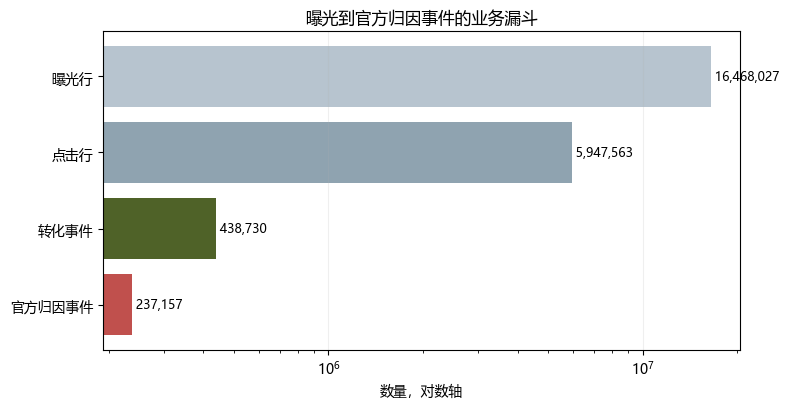

In [3]:
funnel_plot = con.sql("""
SELECT *
FROM funnel_kpi
""").df().iloc[0]

funnel_labels = [
    "曝光行",
    "点击行",
    "转化事件",
    "官方归因事件",
]

funnel_values = [
    funnel_plot["曝光行数"],
    funnel_plot["点击行数"],
    funnel_plot["转化事件数"],
    funnel_plot["官方归因事件数"],
]

fig, ax = plt.subplots(figsize=(8, 4.2))

ax.barh(
    funnel_labels[::-1],
    funnel_values[::-1],
    color=["#C0504D", "#4F6228", "#8FA3B0", "#B7C4CF"],
)

ax.set_xscale("log")
ax.set_xlabel("数量，对数轴")
ax.set_ylabel("")
ax.set_title("曝光到官方归因事件的业务漏斗")

for index, value in enumerate(funnel_values[::-1]):
    ax.text(
        value,
        index,
        f" {int(value):,}",
        va="center",
        fontsize=9,
    )

ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "01_funnel.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

漏斗结果显示，点击之后的转化环节是主要流失点。

绝大多数点击没有形成转化，业务上不能继续把“增加曝光”当作默认动作。
下一步应先下钻活动效率，判断问题是全站普遍存在，还是集中在部分低效活动。

每日趋势

In [4]:
con.execute("""
CREATE OR REPLACE TABLE daily_trend AS
WITH daily AS (
    SELECT
        timestamp // 86400 AS day_idx,
        count(*) AS impressions,
        sum(click) AS clicks,
        sum(conversion) AS conversion_rows,
        sum(cost) AS cost
    FROM raw
    GROUP BY 1
)
SELECT
    day_idx,
    impressions AS "曝光量",
    clicks AS "点击量",
    conversion_rows AS "转化行数",
    round(100.0 * clicks / impressions, 2) AS "点击率(%)",
    round(100.0 * conversion_rows / clicks, 2) AS "点击转化率(%)",
    round(cost, 2) AS "成本",
    CASE
        WHEN day_idx = max(day_idx) OVER () THEN '截断日'
        ELSE '完整日'
    END AS "日期状态"
FROM daily
ORDER BY day_idx
""")

daily = con.sql("""
SELECT *
FROM daily_trend
ORDER BY day_idx
""").df()

daily

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,day_idx,曝光量,点击量,转化行数,点击率(%),点击转化率(%),成本,日期状态
0,0,572035,199240.0,28122.0,34.83,14.11,154.70,完整日
1,1,556092,191217.0,26375.0,34.39,13.79,154.14,完整日
2,2,530015,185646.0,25366.0,35.03,13.66,146.85,完整日
3,3,498596,178933.0,23656.0,35.89,13.22,136.25,完整日
4,4,591180,210162.0,27781.0,35.55,13.22,167.57,完整日
5,5,638165,216961.0,30166.0,34.00,13.90,174.81,完整日
6,6,580979,200642.0,27670.0,34.54,13.79,160.97,完整日
7,7,546166,190126.0,26044.0,34.81,13.70,155.61,完整日
8,8,564794,197149.0,27177.0,34.91,13.79,152.61,完整日
9,9,500383,179719.0,25168.0,35.92,14.00,137.77,完整日


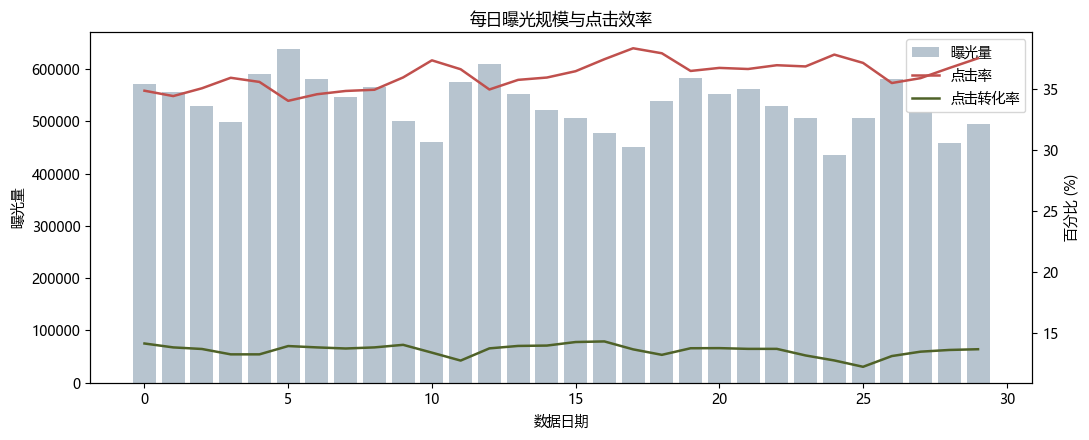

In [5]:
#绘制每日趋势

daily_complete = daily[daily["日期状态"] == "完整日"]

fig, ax1 = plt.subplots(figsize=(11, 4.5))

ax1.bar(
    daily_complete["day_idx"],
    daily_complete["曝光量"],
    color="#B7C4CF",
    label="曝光量"
)
ax1.set_xlabel("数据日期")
ax1.set_ylabel("曝光量")
ax1.set_title("每日曝光规模与点击效率")

ax2 = ax1.twinx()
ax2.plot(
    daily_complete["day_idx"],
    daily_complete["点击率(%)"],
    color="#C0504D",
    linewidth=1.8,
    label="点击率"
)
ax2.plot(
    daily_complete["day_idx"],
    daily_complete["点击转化率(%)"],
    color="#4F6228",
    linewidth=1.8,
    label="点击转化率"
)
ax2.set_ylabel("百分比 (%)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "02_daily_trend.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

在观测完整日的29天内，曝光自然波动，但点击率和转化率整体平稳，没有异动，大盘没问题。
下一步可以看预算花在哪里了？

## 3. 活动效率：预算是否集中在低效活动

漏斗异常只能说明“点击后转化不足”，还不能直接给出预算动作。

本节继续下钻到活动层：

1. 比较活动之间的点击率、转化事件和归因 CPA。
2. 以花费加权 CPA 作为效率基准。
3. 只对归因事件不少于 30 个的活动做动作分类，避免小样本噪声。
4. 用 A/B/C/D 四类动作连接分析结论和预算决策。

In [6]:
#建立活动效率表
con.execute("""
CREATE OR REPLACE TABLE campaign_stats AS
WITH campaign_base AS (
    SELECT
        campaign,
        count(*) AS impressions,
        sum(click) AS clicks,
        sum(conversion) AS conversion_rows,
        count(DISTINCT (uid, conversion_id)) FILTER (
            WHERE conversion = 1
        ) AS conversion_events,
        count(DISTINCT (uid, conversion_id)) FILTER (
            WHERE conversion = 1 AND attribution = 1
        ) AS attributed_events,
        sum(cost) AS cost
    FROM raw
    GROUP BY campaign
)
SELECT
    campaign,
    impressions,
    clicks,
    conversion_rows,
    conversion_events,
    attributed_events,
    cost,
    round(100.0 * clicks / impressions, 2) AS ctr_pct,
    round(
        100.0 * attributed_events / NULLIF(conversion_events, 0),
        2
    ) AS attributed_event_rate_pct,
    round(cost / NULLIF(conversion_events, 0), 4) AS cpa_event,
    round(cost / NULLIF(attributed_events, 0), 4) AS cpa_attributed,
    CASE
        WHEN impressions >= 100000 THEN '头部'
        WHEN impressions >= 10000 THEN '中部'
        ELSE '长尾'
    END AS tier
FROM campaign_base
""")
con.sql("""
SELECT *
FROM campaign_stats
ORDER BY cost DESC
LIMIT 10
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,campaign,impressions,clicks,conversion_rows,conversion_events,attributed_events,cost,ctr_pct,attributed_event_rate_pct,cpa_event,cpa_attributed,tier
0,15398570,378464,135066.0,23853.0,9491,3510,155.572414,35.69,36.98,0.0164,0.0443,头部
1,15184511,256102,93175.0,36995.0,19886,9369,153.826559,36.38,47.11,0.0077,0.0164,头部
2,5061834,299755,85763.0,9861.0,6468,1298,141.244416,28.61,20.07,0.0218,0.1088,头部
3,10341182,437385,194847.0,45479.0,21877,11878,139.162455,44.55,54.29,0.0064,0.0117,头部
4,32368244,161056,77584.0,36638.0,18923,11334,138.096421,48.17,59.90,0.0073,0.0122,头部
5,29427842,239272,79009.0,13797.0,7060,3324,131.092471,33.02,47.08,0.0186,0.0394,头部
6,30491418,186644,72873.0,8234.0,3526,1364,119.051520,39.04,38.68,0.0338,0.0873,头部
7,28351001,222470,138590.0,23230.0,6997,1748,103.700917,62.30,24.98,0.0148,0.0593,头部
8,18975823,217646,100798.0,10575.0,5008,3328,82.155326,46.31,66.45,0.0164,0.0247,头部
9,17686799,381084,112964.0,6486.0,3726,2760,79.429842,29.64,74.07,0.0213,0.0288,头部


In [7]:
#划分 A/B/C/D 动作
con.execute("""
CREATE OR REPLACE TABLE campaign_actions AS
WITH benchmark AS (
    SELECT
        sum(cost) / sum(attributed_events) AS benchmark_cpa
    FROM campaign_stats
    WHERE attributed_events >= 30
)
SELECT
    s.*,
    b.benchmark_cpa,
    CASE
        WHEN s.cost / NULLIF(s.attributed_events, 0)
             <= b.benchmark_cpa
         AND s.attributed_events >= 100
            THEN 'A 加预算'

        WHEN s.cost / NULLIF(s.attributed_events, 0)
             <= b.benchmark_cpa
         AND s.attributed_events < 100
            THEN 'B 观察/扩量测试'

        WHEN s.cost / NULLIF(s.attributed_events, 0)
             > b.benchmark_cpa
         AND s.attributed_events >= 100
            THEN 'C 优化降本'

        ELSE 'D 关停/重定向'
    END AS action
FROM campaign_stats AS s
CROSS JOIN benchmark AS b
WHERE s.attributed_events >= 30
""")
con.sql("""
SELECT *
FROM campaign_actions
ORDER BY cost DESC
LIMIT 10
""").df()

,campaign,impressions,clicks,conversion_rows,conversion_events,attributed_events,cost,ctr_pct,attributed_event_rate_pct,cpa_event,cpa_attributed,tier,benchmark_cpa,action
0,15398570,378464,135066.0,23853.0,9491,3510,155.572414,35.69,36.98,0.0164,0.0443,头部,0.019429,C 优化降本
1,15184511,256102,93175.0,36995.0,19886,9369,153.826559,36.38,47.11,0.0077,0.0164,头部,0.019429,A 加预算
2,5061834,299755,85763.0,9861.0,6468,1298,141.244416,28.61,20.07,0.0218,0.1088,头部,0.019429,C 优化降本
3,10341182,437385,194847.0,45479.0,21877,11878,139.162455,44.55,54.29,0.0064,0.0117,头部,0.019429,A 加预算
4,32368244,161056,77584.0,36638.0,18923,11334,138.096421,48.17,59.90,0.0073,0.0122,头部,0.019429,A 加预算
5,29427842,239272,79009.0,13797.0,7060,3324,131.092471,33.02,47.08,0.0186,0.0394,头部,0.019429,C 优化降本
6,30491418,186644,72873.0,8234.0,3526,1364,119.051520,39.04,38.68,0.0338,0.0873,头部,0.019429,C 优化降本
7,28351001,222470,138590.0,23230.0,6997,1748,103.700917,62.30,24.98,0.0148,0.0593,头部,0.019429,C 优化降本
8,18975823,217646,100798.0,10575.0,5008,3328,82.155326,46.31,66.45,0.0164,0.0247,头部,0.019429,C 优化降本
9,17686799,381084,112964.0,6486.0,3726,2760,79.429842,29.64,74.07,0.0213,0.0288,头部,0.019429,C 优化降本


In [8]:
#生成业务汇总
con.execute("""
CREATE OR REPLACE TABLE campaign_action_summary AS
SELECT
    action,
    count(*) AS campaigns,
    sum(attributed_events) AS attributed_events,
    round(sum(cost), 1) AS cost,
    round(
        100.0 * sum(cost)
        / (SELECT sum(cost) FROM campaign_actions),
        1
    ) AS cost_pct_selected,
    round(
        100.0 * sum(cost)
        / (SELECT sum(cost) FROM campaign_stats),
        1
    ) AS cost_pct_all,
    round(sum(cost) / sum(attributed_events), 4) AS cpa_attributed
FROM campaign_actions
GROUP BY action
ORDER BY action
""")

con.execute("""
CREATE OR REPLACE TABLE campaign_gap AS
WITH grouped AS (
    SELECT
        CASE
            WHEN cost / NULLIF(attributed_events, 0)
                 <= benchmark_cpa
                THEN '高效组'
            ELSE '低效组'
        END AS efficiency_group,
        count(*) AS campaigns,
        sum(cost) AS total_cost,
        sum(attributed_events) AS attributed_events
    FROM campaign_actions
    GROUP BY 1
)
SELECT
    efficiency_group,
    campaigns,
    round(total_cost, 1) AS total_cost,
    attributed_events,
    round(total_cost / attributed_events, 4) AS cpa_attributed
FROM grouped
ORDER BY efficiency_group
""")

from IPython.display import display

action_summary = con.sql("""
SELECT *
FROM campaign_action_summary
""").df()

efficiency_gap = con.sql("""
SELECT *
FROM campaign_gap
""").df()

coverage = con.sql("""
SELECT
    (SELECT count(*) FROM campaign_actions) AS analyzed_campaigns,
    (SELECT count(*) FROM campaign_stats) AS total_campaigns,
    round(
        100.0 * (SELECT sum(cost) FROM campaign_actions)
        / (SELECT sum(cost) FROM campaign_stats),
        1
    ) AS analyzed_cost_pct
""").df()

display(coverage)
display(action_summary)
display(efficiency_gap)

,analyzed_campaigns,total_campaigns,analyzed_cost_pct
0,488,675,94.1


,action,campaigns,attributed_events,cost,cost_pct_selected,cost_pct_all,cpa_attributed
0,A 加预算,104,154663.0,954.3,21.0,19.8,0.0062
1,B 观察/扩量测试,51,3025.0,39.9,0.9,0.8,0.0132
2,C 优化降本,155,66395.0,2917.5,64.2,60.4,0.0439
3,D 关停/重定向,178,9887.0,634.0,13.9,13.1,0.0641


,efficiency_group,campaigns,total_cost,attributed_events,cpa_attributed
0,低效组,333,3551.5,76282.0,0.0466
1,高效组,155,994.3,157688.0,0.0063


1.账户预算分配不健康，绝大部分预算给了C/D，高效与低效CPA差一个数量级
2.头部少数计划高效，长尾大量计划低效烧钱
3.低效组集中了约四分之三的全站成本，高效组只占约两成。下一步的预算动作应当优先发生在 C、D 类活动，而不是继续平均增加所有活动的曝光。.建议优化关停C/D，释放预算倾斜给A，B继续观察或者小规模测试

但该结果只是基于历史数据的组内相对比较。落地前仍需要小预算 A/B 测试。

,campaign,action,tier,impressions,ctr_pct,conversion_events,attributed_events,cost,cpa_attributed
0,15398570,C 优化降本,头部,378464,35.69,9491,3510,155.6,0.0443
1,15184511,A 加预算,头部,256102,36.38,19886,9369,153.8,0.0164
2,5061834,C 优化降本,头部,299755,28.61,6468,1298,141.2,0.1088
3,10341182,A 加预算,头部,437385,44.55,21877,11878,139.2,0.0117
4,32368244,A 加预算,头部,161056,48.17,18923,11334,138.1,0.0122
5,29427842,C 优化降本,头部,239272,33.02,7060,3324,131.1,0.0394
6,30491418,C 优化降本,头部,186644,39.04,3526,1364,119.1,0.0873
7,28351001,C 优化降本,头部,222470,62.30,6997,1748,103.7,0.0593
8,18975823,C 优化降本,头部,217646,46.31,5008,3328,82.2,0.0247
9,17686799,C 优化降本,头部,381084,29.64,3726,2760,79.4,0.0288


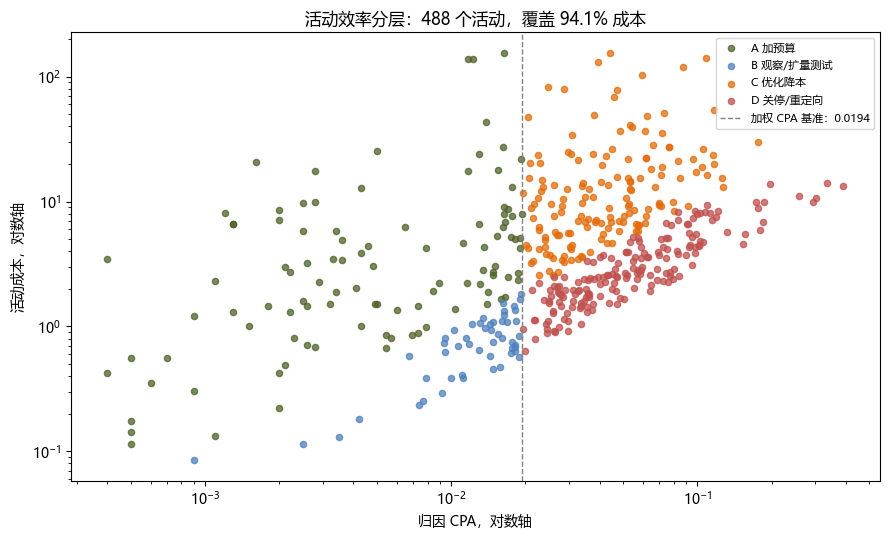

In [9]:
#查看高成本活动并绘图
top_campaigns = con.sql("""
SELECT
    campaign,
    action,
    tier,
    impressions,
    ctr_pct,
    conversion_events,
    attributed_events,
    round(cost, 1) AS cost,
    cpa_attributed
FROM campaign_actions
ORDER BY cost DESC
LIMIT 12
""").df()

display(top_campaigns)

actions = con.sql("""
SELECT *
FROM campaign_actions
""").df()

stats = con.sql("""
SELECT *
FROM campaign_stats
""").df()

benchmark_cpa = actions["benchmark_cpa"].iloc[0]
cost_coverage = 100 * actions["cost"].sum() / stats["cost"].sum()

colors = {
    "A 加预算": "#4F6228",
    "B 观察/扩量测试": "#4F81BD",
    "C 优化降本": "#E36C0A",
    "D 关停/重定向": "#C0504D"
}

fig, ax = plt.subplots(figsize=(9, 5.5))

for action in sorted(actions["action"].unique()):
    subset = actions[actions["action"] == action]
    ax.scatter(
        subset["cpa_attributed"],
        subset["cost"],
        s=20,
        alpha=0.75,
        color=colors[action],
        label=action
    )

ax.axvline(
    benchmark_cpa,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"加权 CPA 基准：{benchmark_cpa:.4f}"
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("归因 CPA，对数轴")
ax.set_ylabel("活动成本，对数轴")
ax.set_title(
    f"活动效率分层：{len(actions)} 个活动，覆盖 {cost_coverage:.1f}% 成本"
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "03_campaign_efficiency.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

## 4. 位置归因：哪些转化路径可以使用

一个转化事件可能包含多次点击，每行只代表其中一个触点。

为了分析位置价值，需要先区分两种数据粒度：

- 转化事件粒度：一行一个 `(uid, conversion_id)`，用于计算事件成本、归因和路径是否完整。
- 路径触点粒度：一行一个点击触点，用于比较首次、中间和末次点击。

位置归因只使用完整路径。否则，缺失的首次或末次点击会被当前观测到的端点替代，导致位置成本被错误分配。

In [10]:
#建立转化事件表
con.execute("""
CREATE OR REPLACE TABLE conversion_events AS
WITH event_base AS (
    SELECT
        uid,
        conversion_id,
        min(conversion_timestamp) AS conv_ts,
        any_value(campaign) AS campaign,
        count(*) AS rows_present,
        max(click_nb) AS path_len,
        min(click_pos) AS min_pos,
        max(click_pos) AS max_pos,
        count(*) FILTER (
            WHERE attribution = 1
        ) AS attr_rows,
        count(*) FILTER (
            WHERE click_pos = click_nb - 1
        ) AS last_click_rows,
        sum(cost) AS path_cost
    FROM raw
    WHERE conversion = 1
    GROUP BY uid, conversion_id
)
SELECT
    uid,
    conversion_id,
    campaign,
    conv_ts,
    conv_ts // 86400 AS event_day,
    rows_present,
    path_len,
    path_cost,
    attr_rows,
    last_click_rows,
    rows_present = path_len AS is_path_complete,
    min_pos = 0 AS has_first_click,
    max_pos = path_len - 1 AS has_last_click,
    path_len = 1 AS is_single_click_path,
    attr_rows > 0 AS is_attributed
FROM event_base
""")
con.sql("""
SELECT *
FROM conversion_events
ORDER BY path_cost DESC
LIMIT 5
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,uid,conversion_id,campaign,conv_ts,event_day,rows_present,path_len,path_cost,attr_rows,last_click_rows,is_path_complete,has_first_click,has_last_click,is_single_click_path,is_attributed
0,5543542,2205467,12987593,2450672,28,54,54,1.572264,54,1,True,True,True,False,True
1,8509354,12860175,497593,1684248,19,68,68,1.302532,68,1,True,True,True,False,True
2,32412948,28432677,14661605,1842618,21,48,70,0.946345,48,1,False,False,True,False,True
3,13205758,3225316,10341182,854954,9,41,41,0.820844,41,1,True,True,True,False,True
4,15811903,5901215,30491418,642118,7,30,75,0.635508,30,1,False,False,True,False,True


In [11]:
#建立路径触点表
con.execute("""
CREATE OR REPLACE TABLE conversion_path AS
SELECT
    p.timestamp,
    p.uid,
    p.conversion_id,
    p.campaign,
    p.timestamp // 86400 AS day_idx,
    (p.timestamp % 86400) // 3600 AS hour_of_day,
    p.conversion_timestamp - p.timestamp AS conv_delay_sec,
    (p.conversion_timestamp - p.timestamp) / 86400.0
        AS conv_delay_days,
    p.click_pos AS path_pos,
    p.click_nb AS path_len,
    p.click_pos = 0 AS is_first_click,
    p.click_pos = p.click_nb - 1 AS is_last_click,
    p.cost,
    p.cost <= 1.0001e-05 AS cost_is_floor,
    p.attribution,
    p.attribution = 1 AS is_attributed,
    e.rows_present,
    e.is_path_complete,
    e.has_first_click,
    e.has_last_click,
    e.is_single_click_path,
    e.attr_rows
FROM raw AS p
JOIN conversion_events AS e
    USING (uid, conversion_id)
WHERE p.conversion = 1
""")

con.sql("""
SELECT *
FROM conversion_path
ORDER BY cost DESC
LIMIT 5
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,timestamp,uid,conversion_id,campaign,day_idx,hour_of_day,conv_delay_sec,conv_delay_days,path_pos,path_len,...,cost,cost_is_floor,attribution,is_attributed,rows_present,is_path_complete,has_first_click,has_last_click,is_single_click_path,attr_rows
0,572353,15811903,5901215,30491418,6,14,69765,0.807465,67,75,...,0.057756,False,1,True,30,False,False,True,False,30
1,551044,9634988,16253083,28351001,6,9,396171,4.585312,0,12,...,0.057502,False,1,True,12,True,True,True,False,12
2,2036153,5543542,2205467,12987593,23,13,414519,4.797674,38,54,...,0.056817,False,1,True,54,True,True,True,False,54
3,1978146,5543542,2205467,12987593,22,21,472526,5.469051,35,54,...,0.056663,False,1,True,54,True,True,True,False,54
4,2093388,5543542,2205467,12987593,24,5,357284,4.135231,43,54,...,0.056620,False,1,True,54,True,True,True,False,54


In [12]:
#建立路径覆盖率证据
con.execute("""
CREATE OR REPLACE TABLE path_coverage AS
SELECT
    count(*) AS "转化事件数",
    count(*) FILTER (
        WHERE is_path_complete
    ) AS "完整路径事件数",
    round(
        100.0 * count(*) FILTER (
            WHERE is_path_complete
        ) / count(*),
        2
    ) AS "完整路径事件占比(%)",
    count(*) FILTER (
        WHERE NOT has_first_click
    ) AS "缺少首次点击事件数",
    round(
        100.0 * count(*) FILTER (
            WHERE NOT has_first_click
        ) / count(*),
        2
    ) AS "缺少首次点击占比(%)",
    count(*) FILTER (
        WHERE NOT has_last_click
    ) AS "缺少末次点击事件数",
    round(
        100.0 * count(*) FILTER (
            WHERE NOT has_last_click
        ) / count(*),
        2
    ) AS "缺少末次点击占比(%)",
    count(*) FILTER (
        WHERE is_single_click_path
    ) AS "单点击路径事件数",
    round(
        100.0 * count(*) FILTER (
            WHERE is_single_click_path
        ) / count(*),
        2
    ) AS "单点击路径占比(%)",
    count(*) FILTER (
        WHERE is_attributed
    ) AS "官方归因事件数",
    round(
        100.0 * count(*) FILTER (
            WHERE is_attributed
        ) / count(*),
        2
    ) AS "官方归因事件占比(%)",
    round(sum(path_cost), 2) AS "全部转化路径成本",
    round(
        sum(path_cost) FILTER (
            WHERE is_path_complete
        ),
        2
    ) AS "完整路径成本"
FROM conversion_events
""")

coverage = con.sql("""
SELECT *
FROM path_coverage
""").df().T.reset_index()

coverage.columns = ["指标", "数值"]
coverage

,指标,数值
0,转化事件数,438730.00
1,完整路径事件数,362504.00
2,完整路径事件占比(%),82.63
3,缺少首次点击事件数,38578.00
4,缺少首次点击占比(%),8.79
5,缺少末次点击事件数,37648.00
6,缺少末次点击占比(%),8.58
7,单点击路径事件数,260774.00
8,单点击路径占比(%),59.44
9,官方归因事件数,237157.00


In [13]:
#检查事件表与路径表
path_check = con.sql("""
SELECT
    (SELECT count(*) FROM conversion_events) AS events,
    (SELECT count(*) FROM conversion_path) AS path_rows,
    (
        SELECT count(*)
        FROM conversion_path
        WHERE is_path_complete
    ) AS complete_path_rows,
    (
        SELECT count(*)
        FROM conversion_path
        WHERE is_last_click
    ) AS last_click_rows,
    (
        SELECT round(sum(cost), 2)
        FROM conversion_path
    ) AS path_cost,
    (
        SELECT count(DISTINCT campaign)
        FROM conversion_path
    ) AS campaigns
""").df().T.reset_index()

path_check.columns = ["指标", "数值"]
path_check

,指标,数值
0,events,438730.00
1,path_rows,806196.00
2,complete_path_rows,600145.00
3,last_click_rows,401082.00
4,path_cost,802.44
5,campaigns,675.00


完整路径只覆盖 82.63% 的转化事件，但覆盖了 72.3% 的转化路径成本。

因此，后续触点位置结论只代表拥有完整点击路径的预算部分，不能直接外推到全部 802.44 的路径成本，更不能外推到全站成本。

这不是需要删除的“数据问题”，而是位置出价建议最重要的适用边界。

In [14]:
#路径长度分布
con.execute("""
CREATE OR REPLACE TABLE path_length_distribution AS
SELECT
    path_len,
    count(*) AS events,
    count(*) FILTER (
        WHERE is_path_complete
    ) AS complete_events,
    count(*) FILTER (
        WHERE is_attributed
    ) AS attributed_events,
    round(
        100.0 * count(*) FILTER (
            WHERE is_attributed
        ) / count(*),
        2
    ) AS attribution_rate_pct
FROM conversion_events
GROUP BY path_len
ORDER BY path_len
""")

path_length = con.sql("""
SELECT *
FROM path_length_distribution
ORDER BY path_len
""").df()

path_length.head(30)

,path_len,events,complete_events,attributed_events,attribution_rate_pct
0,1,260774,260774,141709,54.34
1,2,77231,55288,40634,52.61
2,3,35759,20654,18803,52.58
3,4,19617,9687,10511,53.58
4,5,12017,5201,6490,54.01
5,6,8087,3235,4442,54.93
6,7,5661,2058,3159,55.80
7,8,4078,1395,2289,56.13
8,9,2976,1022,1711,57.49
9,10,2242,685,1327,59.19


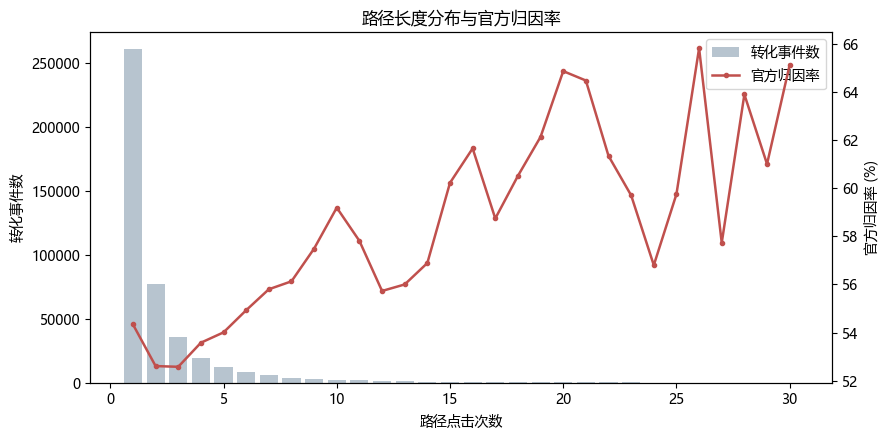

In [15]:
#绘制路径长度与归因率

path_plot = path_length[path_length["path_len"] <= 30]

fig, ax1 = plt.subplots(figsize=(9, 4.5))

ax1.bar(
    path_plot["path_len"],
    path_plot["events"],
    color="#B7C4CF",
    label="转化事件数"
)
ax1.set_xlabel("路径点击次数")
ax1.set_ylabel("转化事件数")

ax2 = ax1.twinx()
ax2.plot(
    path_plot["path_len"],
    path_plot["attribution_rate_pct"],
    color="#C0504D",
    linewidth=1.8,
    marker="o",
    markersize=3,
    label="官方归因率"
)
ax2.set_ylabel("官方归因率 (%)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

ax1.set_title("路径长度分布与官方归因率")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "04_path_length.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [16]:
con.close()